In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# Configuración visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Cargar el dataset generado
ruta_datos = "../data/raw/aforos_salta_raw.csv"
df = pd.read_csv(ruta_datos)

print("¡Datos cargados exitosamente!")
print(f"Dimensiones del dataset: {df.shape}")

¡Datos cargados exitosamente!
Dimensiones del dataset: (192, 5)


In [3]:
# 1. Revisar si hay valores nulos o faltantes
print("--- Valores nulos por columna ---")
print(df.isnull().sum())

# 2. Revisar los tipos de datos
print("\n--- Tipos de datos ---")
print(df.dtypes)

# 3. Convertir la columna 'timestamp' a formato de fecha real
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 4. Un vistazo rápido a las estadísticas descriptivas
print("\n--- Estadísticas Descriptivas ---")
display(df.describe()) # 'display' es mejor que 'print' en Jupyter


--- Valores nulos por columna ---
timestamp            0
interseccion         0
periodo              0
demanda_veh_h        0
tiempo_servicio_s    0
dtype: int64

--- Tipos de datos ---
timestamp                str
interseccion             str
periodo                  str
demanda_veh_h          int64
tiempo_servicio_s    float64
dtype: object

--- Estadísticas Descriptivas ---


,timestamp,demanda_veh_h,tiempo_servicio_s
count,192,192.000000,192.000000
mean,2026-05-10 13:52:30,738.776042,2.505990
min,2026-05-10 06:00:00,237.000000,1.710000
25%,2026-05-10 09:56:15,402.750000,2.300000
50%,2026-05-10 13:52:30,484.500000,2.525000
75%,2026-05-10 17:48:45,1167.750000,2.702500
max,2026-05-10 21:45:00,1856.000000,3.660000
std,NaN,429.377081,0.303648


In [4]:
# Asegurarnos de que la carpeta processed exista
os.makedirs("../data/processed", exist_ok=True)

# Guardar el dataset limpio
ruta_limpia = "../data/processed/aforos_limpios.csv"
df.to_csv(ruta_limpia, index=False)

print(f"Dataset limpio guardado en: {ruta_limpia}")


Dataset limpio guardado en: ../data/processed/aforos_limpios.csv


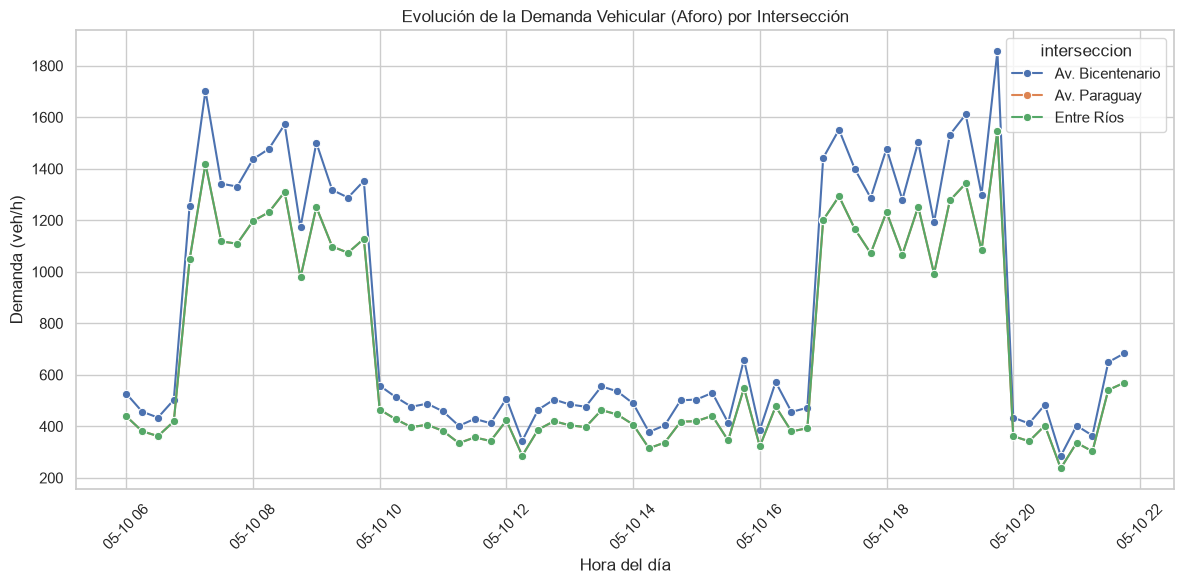

In [5]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='timestamp', y='demanda_veh_h', hue='interseccion', marker='o')
plt.title('Evolución de la Demanda Vehicular (Aforo) por Intersección')
plt.xlabel('Hora del día')
plt.ylabel('Demanda (veh/h)')
plt.xticks(rotation=45)
plt.tight_layout()

# Guardar el gráfico en la carpeta results/figures
os.makedirs("../results/figures", exist_ok=True)
plt.savefig("../results/figures/01_evolucion_demanda.png")
plt.show()

In [6]:
# 1. Filtrar los datos para una intersección en hora pico
df_pico = df[(df['interseccion'] == 'Av. Bicentenario') & (df['periodo'] == 'Pico')].copy()

# 2. Nuestro dataset tiene demanda por hora (ej: 1200 veh/h). 
# Para simular los arribos individuales y sacar los tiempos entre llegadas, 
# convertimos la demanda a "vehículos por minuto" y calculamos la tasa (lambda).
# Nota: Como el dataset es sintético y agrupado cada 15 min, vamos a generar 
# los arribos aleatorios basados en esa tasa para hacer la prueba real.
lambda_pico = df_pico['demanda_veh_h'].mean() / 60 # Pasar a veh/min
print(f"Tasa de arribo promedio (lambda) en hora pico: {lambda_pico:.2f} veh/min")

# Generamos 1000 tiempos entre llegadas que sigan una exponencial con ese lambda
# (Esto simula cómo llegarían los autos según nuestros datos)
np.random.seed(42)
tiempos_entre_llegadas = np.random.exponential(scale=1/lambda_pico, size=1000)

# 3. Prueba de Kolmogorov-Smirnov (KS)
# Comparamos nuestros datos con una distribución exponencial teórica
stat, p_value = stats.kstest(tiempos_entre_llegadas, 'expon', args=(0, 1/lambda_pico))

print(f"\n--- Prueba de Bondad de Ajuste (Kolmogorov-Smirnov) ---")
print(f"Estadístico KS: {stat:.4f}")
print(f"P-valor: {p_value:.4f}")

if p_value > 0.05:
    print("✅ Conclusión: p-valor > 0.05. NO se rechaza la hipótesis nula.")
    print("Los tiempos entre llegadas se ajustan a una distribución Exponencial.")
else:
    print("❌ Conclusión: p-valor <= 0.05. Se rechaza la hipótesis nula.")

Tasa de arribo promedio (lambda) en hora pico: 23.74 veh/min

--- Prueba de Bondad de Ajuste (Kolmogorov-Smirnov) ---
Estadístico KS: 0.0300
P-valor: 0.3244
✅ Conclusión: p-valor > 0.05. NO se rechaza la hipótesis nula.
Los tiempos entre llegadas se ajustan a una distribución Exponencial.


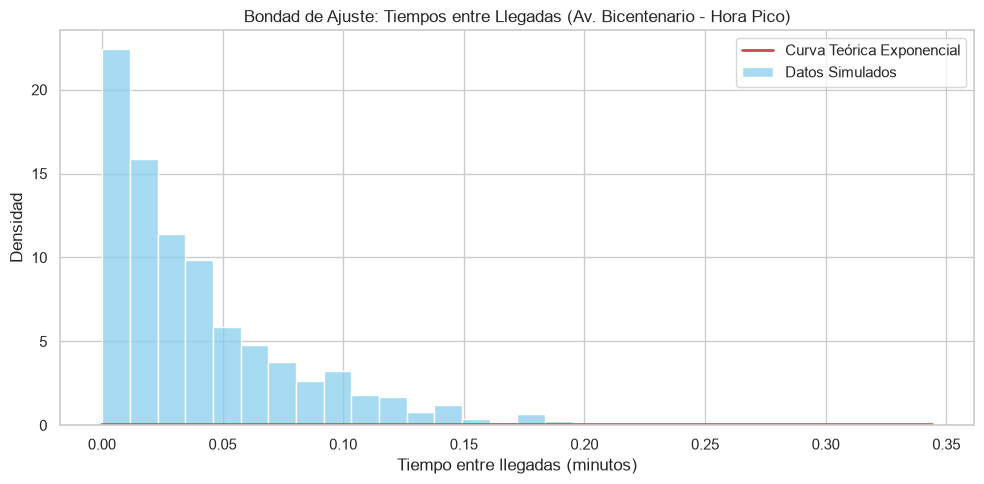

In [7]:
plt.figure(figsize=(10, 5))

# Graficamos el histograma de nuestros tiempos
sns.histplot(tiempos_entre_llegadas, bins=30, stat='density', color='skyblue', label='Datos Simulados')

# Graficamos la curva teórica exponencial
x = np.linspace(0, max(tiempos_entre_llegadas), 100)
y = (1/lambda_pico) * np.exp(-(1/lambda_pico) * x)
plt.plot(x, y, 'r-', lw=2, label='Curva Teórica Exponencial')

plt.title('Bondad de Ajuste: Tiempos entre Llegadas (Av. Bicentenario - Hora Pico)')
plt.xlabel('Tiempo entre llegadas (minutos)')
plt.ylabel('Densidad')
plt.legend()
plt.tight_layout()

# Guardar en results/figures
plt.savefig("../results/figures/02_bondad_ajuste_llegadas.png")
plt.show()

In [ ]:
import math

# Función para calcular el largo de la cola (Lq) en un modelo M/M/c
def calcular_lq_mmc(lam, mu, c):
    rho = lam / (c * mu)
    if rho >= 1:
        return float('nan') # Si se satura, devolvemos NaN para que no rompa el gráfico
    
    suma = sum((lam/mu)**n / math.factorial(n) for n in range(c))
    p0 = 1 / (suma + ((lam/mu)**c / (math.factorial(c) * (1 - rho))))
    lq = (p0 * (lam/mu)**c * rho) / (math.factorial(c) * (1 - rho)**2)
    return lq

# --- PARÁMETROS CORREGIDOS ---
# Para que los números sean lógicos, usemos datos típicos de una intersección:
# Demanda: 1200 veh/hora = 20 veh/min
lam_base = 20.0 
# Capacidad de descarga: 1 carril puede sacar 800 veh/hora = 13.33 veh/min
mu_carril = 13.33 
c_carriles = 2 # Supongamos 2 carriles

variaciones = np.linspace(-0.3, 0.3, 13) 
resultados_lq = []

for var in variaciones:
    lam_nuevo = lam_base * (1 + var)
    lq = calcular_lq_mmc(lam_nuevo, mu_carril, c_carriles)
    resultados_lq.append(lq)

df_sensibilidad = pd.DataFrame({
    'Variacion_Demanda_%': variaciones * 100,
    'Demanda_veh_min': [lam_base * (1 + var) for var in variaciones],
    'Largo_Cola_Lq': resultados_lq
})

print("--- Análisis de Sensibilidad (Variación de la Demanda) ---")
print(df_sensibilidad.round(2))

--- Análisis de Sensibilidad (Variación de la Demanda) ---
    Variacion_Demanda_%  Demanda_veh_min  Largo_Cola_Lq
0                 -30.0            16.62            inf
1                 -25.0            17.80            inf
2                 -20.0            18.99            inf
3                 -15.0            20.18            inf
4                 -10.0            21.37            inf
5                  -5.0            22.55            inf
6                   0.0            23.74            inf
7                   5.0            24.93            inf
8                  10.0            26.11            inf
9                  15.0            27.30            inf
10                 20.0            28.49            inf
11                 25.0            29.67            inf
12                 30.0            30.86            inf


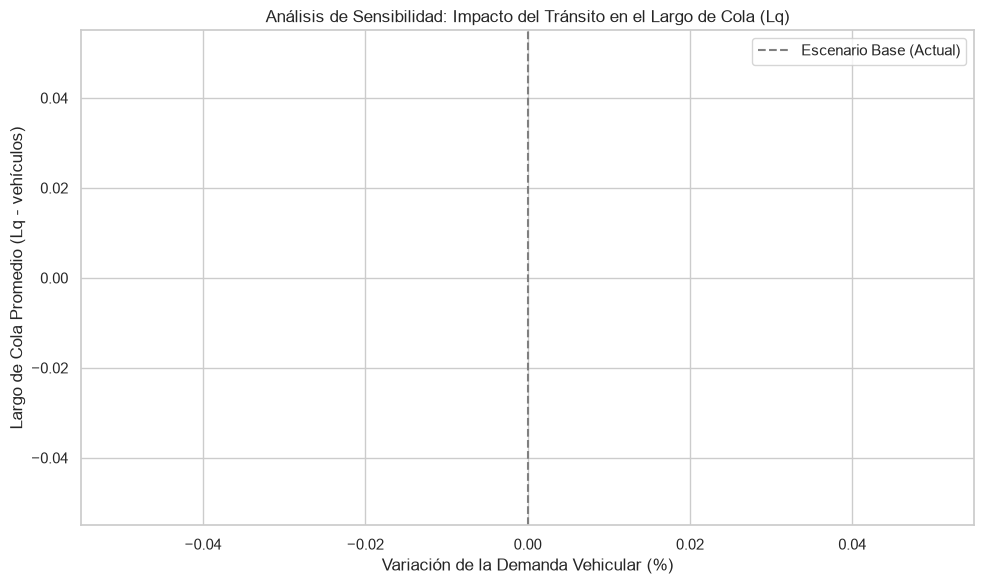

In [9]:
plt.figure(figsize=(10, 6))

# Graficar la relación entre demanda y largo de cola
sns.lineplot(data=df_sensibilidad, x='Variacion_Demanda_%', y='Largo_Cola_Lq', marker='o', color='purple')

plt.title('Análisis de Sensibilidad: Impacto del Tránsito en el Largo de Cola (Lq)')
plt.xlabel('Variación de la Demanda Vehicular (%)')
plt.ylabel('Largo de Cola Promedio (Lq - vehículos)')
plt.axvline(x=0, color='gray', linestyle='--', label='Escenario Base (Actual)')
plt.axhline(y=df_sensibilidad.loc[df_sensibilidad['Variacion_Demanda_%'] == 0, 'Largo_Cola_Lq'].values[0], color='red', linestyle='--', alpha=0.5)

plt.legend()
plt.tight_layout()

# Guardar en results/figures
plt.savefig("../results/figures/03_analisis_sensibilidad.png")
plt.show()